# Essay writing by llm -> evaluate it -> publish it if its good, else bakc to essay write with feedback

In [1]:
from typing import TypedDict, Annotated
import operator

class EssayState(TypedDict):
    topic : str
    essay : str
    feedback : Annotated[list[str],operator.add]
    score : int
    revision_cnt : int

In [2]:
from pydantic import BaseModel , Field

class CriticOp(BaseModel):
    feedback : str = Field(description="Feedback for essay")
    score : int = Field(description="Give the score for essay, it shoud be between 0 and 10", gt=0,le=10)

# define llm

In [3]:
import os 
from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()

llm_writer = ChatGroq(model = "openai/gpt-oss-20b")
llm_critic = ChatGroq(model = "openai/gpt-oss-20b")
llm_structured_critc = llm_critic.with_structured_output(schema=CriticOp)

In [4]:
# defining nodes
from langchain_core.prompts import ChatPromptTemplate

def essayWrite(state : EssayState):
    print("Node essayWrite started")
    
    systemMessage = """ You are a good essay writer, for the given topic , write essay within 100 words.
        Essay should include latest upto date knwolwedge, adavantages and disadvantage and conclusion.
    """

    messages = [
        ("system", systemMessage),
        ("human",state["topic"])
    ]

    essay = llm_writer.invoke(messages).content


    revision_cnt = state.get("revision_cnt",-1) + 1
    return {
        "essay" : essay,
        "revision_cnt":revision_cnt
    }

def essayCritic(state : EssayState):
    print("Node essayCritic started")
    
    systemMessage = """ You are good critic assistant. For given essay , give the feedback in 10 words ONLY and score ,which is structured, 
    based on language, enough context and the outline.
    """

    messages = [
        ("system",systemMessage),
        ("human",state["essay"])
    ]
    response = llm_structured_critc.invoke(messages)

    print(f"********resposne : {response}")
    return {
       "feedback" :[response.feedback],
       "score" : response.score
    }

def publish(state : EssayState):
    print("Node publish started")

def routingCondition(state : EssayState):
    score = state["score"]
    print(state["revision_cnt"] )
    if score >= 5 or state["revision_cnt"] >= 3:
        return "publish"
    else:
        return "essayWrite"



In [5]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(state_schema=EssayState)

# nodes
graph.add_node("essayWrite",essayWrite)
graph.add_node("essayCritic",essayCritic)
graph.add_node("publish",publish)

# add edges
graph.add_edge(START, "essayWrite")
graph.add_edge("essayWrite","essayCritic")
graph.add_conditional_edges("essayCritic",routingCondition, {"publish":"publish","essayWrite":"essayWrite"})
graph.add_edge("publish",END)

workflow = graph.compile()
intitial_state = {"topic":"AI latest update"}
final_state = workflow.invoke(input = intitial_state)


Node essayWrite started
Node essayCritic started
********resposne : feedback='Clear, concise, comprehensive; lacks deeper analysis of regulatory nuances overall.' score=8
0
Node publish started


In [6]:
final_state

{'topic': 'AI latest update',
 'essay': 'Recent AI updates, notably GPT‑5, Claude\u202f3.5, and Gemini\u202f1.5, bring multimodal reasoning, reduced token limits, and energy‑efficient architectures. They now understand context across text, image, audio, and code with near‑human accuracy, enabling advanced content creation, coding, and scientific research. Benefits include faster inference, lower carbon footprint, and safer alignment mechanisms such as prompt‑based safety filters and differential privacy. Risks remain: residual bias, hallucinations, potential weaponization, and data‑privacy concerns. A balanced regulatory framework, transparent model cards, and continuous monitoring are essential to harness AI’s promise while mitigating its perils.',
 'feedback': ['Clear, concise, comprehensive; lacks deeper analysis of regulatory nuances overall.'],
 'score': 8,
 'revision_cnt': 0}

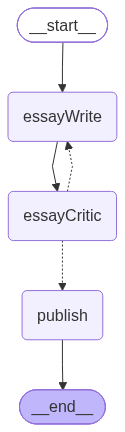

In [7]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())